# Step 1 Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

# Load dataset
df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Explore

In [2]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Data types
print("\nData types:")
print(df.dtypes.value_counts())

# Column information
print("\nColumn information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget proportions:")
print(df["y"].value_counts(normalize=True))

# Positive-class proportion
positive_proportion = (df["y"] == "yes").mean()
print(f"\nPositive-class proportion: {positive_proportion:.4%}")

Number of rows: 41188
Number of columns: 21

Data types:
object     11
int64       5
float64     5
Name: count, dtype: int64

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        4118

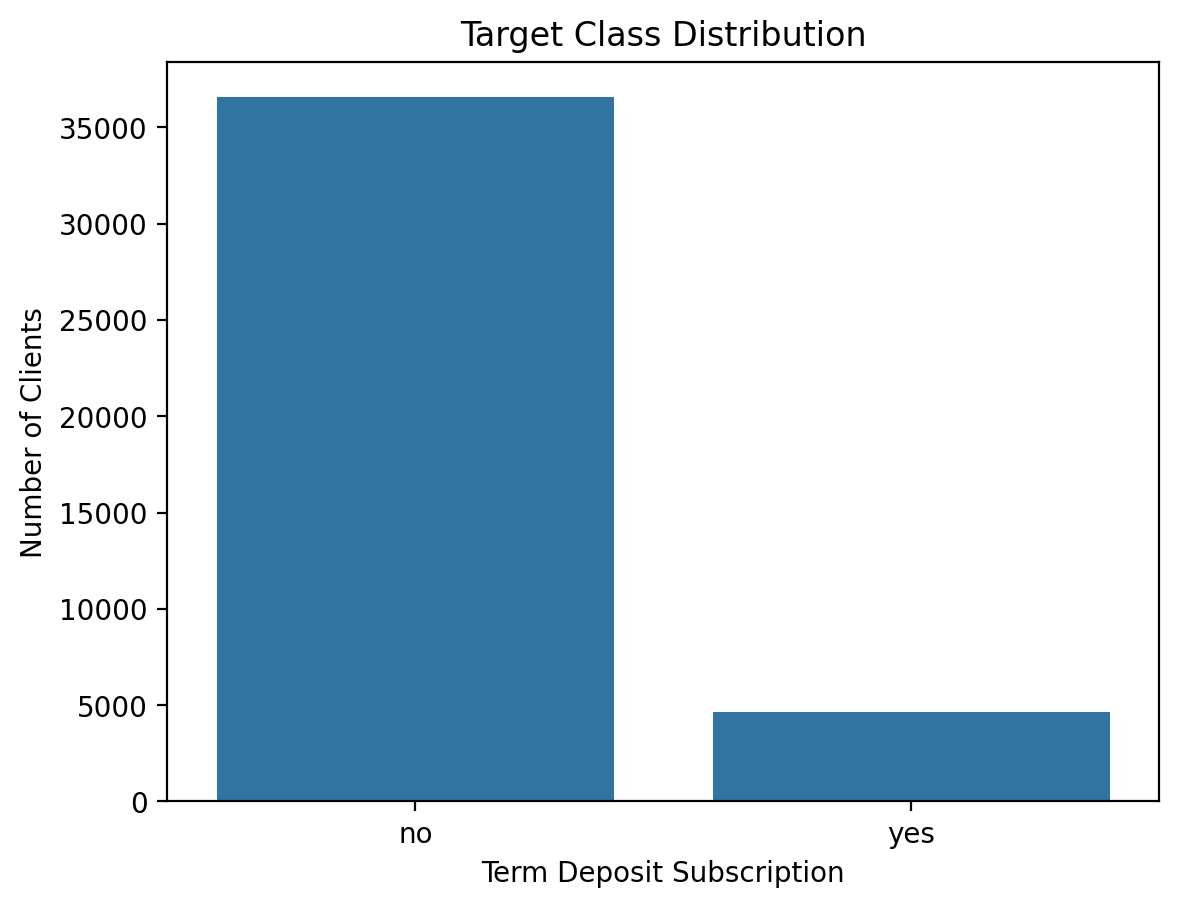

In [3]:
sns.countplot(data=df, x="y")

plt.title("Target Class Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Clients")
plt.show()

## Unknown categorical values

In [4]:
categorical_cols = df.select_dtypes(include="object").columns.drop("y")

print("Unknown categorical values:\n")

for col in categorical_cols:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(f"{col}: {count} ({count / len(df):.2%})")

Unknown categorical values:

job: 330 (0.80%)
marital: 80 (0.19%)
education: 1731 (4.20%)
default: 8597 (20.87%)
housing: 990 (2.40%)
loan: 990 (2.40%)


In [5]:
print("Number of pdays = 999:", (df["pdays"] == 999).sum())
print(
    "Percentage of pdays = 999:",
    f"{(df['pdays'] == 999).mean():.2%}"
)

Number of pdays = 999: 39673
Percentage of pdays = 999: 96.32%


## Clean the dataset

In [6]:
# Create indicator for whether the client was previously contacted
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

# Replace special value 999 with NaN
df["pdays"] = df["pdays"].replace(999, np.nan)

# Remove duration 
df = df.drop(columns=["duration"])

# Separate predictors and target
X = df.drop(columns=["y"])
y = (df["y"] == "yes").astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Predictor shape: (41188, 20)
Target shape: (41188,)

Target distribution:
y
0    0.887346
1    0.112654
Name: proportion, dtype: float64


## Create train/validation/test splits

In [7]:
# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Display split sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (28831, 20)
Validation set: (6178, 20)
Test set: (6179, 20)


## Check class proportion

In [8]:
split_summary = pd.DataFrame({
    "Dataset": ["Overall", "Training", "Validation", "Test"],
    "Rows": [len(y), len(y_train), len(y_val), len(y_test)],
    "Positive Class Proportion": [
        y.mean(),
        y_train.mean(),
        y_val.mean(),
        y_test.mean()
    ]
})

split_summary["Positive Class Proportion"] = (
    split_summary["Positive Class Proportion"].map(lambda x: f"{x:.4%}")
)

display(split_summary)

,Dataset,Rows,Positive Class Proportion
0,Overall,41188,11.2654%
1,Training,28831,11.2657%
2,Validation,6178,11.2658%
3,Test,6179,11.2640%


## Preprocessing

In [9]:
# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 10
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [10]:
# Numerical preprocessing for GBDT
numeric_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Numerical preprocessing for MLP
numeric_mlp = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# GBDT preprocessing
preprocessor_gbdt = ColumnTransformer([
    ("num", numeric_tree, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# MLP preprocessing
preprocessor_mlp = ColumnTransformer([
    ("num", numeric_mlp, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [11]:
# GBDT preprocessing
X_train_gbdt = preprocessor_gbdt.fit_transform(X_train)
X_val_gbdt = preprocessor_gbdt.transform(X_val)
X_test_gbdt = preprocessor_gbdt.transform(X_test)

# MLP preprocessing
X_train_mlp = preprocessor_mlp.fit_transform(X_train)
X_val_mlp = preprocessor_mlp.transform(X_val)
X_test_mlp = preprocessor_mlp.transform(X_test)

print("GBDT transformed shapes:")
print("Training:", X_train_gbdt.shape)
print("Validation:", X_val_gbdt.shape)
print("Test:", X_test_gbdt.shape)

print("\nMLP transformed shapes:")
print("Training:", X_train_mlp.shape)
print("Validation:", X_val_mlp.shape)
print("Test:", X_test_mlp.shape)

GBDT transformed shapes:
Training: (28831, 63)
Validation: (6178, 63)
Test: (6179, 63)

MLP transformed shapes:
Training: (28831, 63)
Validation: (6178, 63)
Test: (6179, 63)


# Step 2 Gradient Boosted Trees (GBDT)

In [ ]:
import xgboost as xgb
import time
from sklearn.metrics import average_precision_score, log_loss

## Define the function

In [ ]:
def run_gbdt_experiment(
    experiment_name,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    reg_lambda=1.0
):
    model = xgb.XGBClassifier(
        n_estimators=1000,
        learning_rate=learning_rate,
        max_depth=max_depth,
        subsample=subsample,
        reg_lambda=reg_lambda,
        tree_method="hist",
        eval_metric="logloss",
        early_stopping_rounds=30,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    start_time = time.perf_counter()

    model.fit(
        X_train_gbdt,
        y_train,
        eval_set=[
            (X_train_gbdt, y_train),
            (X_val_gbdt, y_val)
        ],
        verbose=False
    )
    fit_time = time.perf_counter() - start_time

    # Validation predictions
    val_probabilities = model.predict_proba(X_val_gbdt)[:, 1]
    # Validation metrics
    val_ap = average_precision_score(
        y_val, val_probabilities
    )
    val_logloss = log_loss(
        y_val, val_probabilities
    )
    results = {
        "experiment": experiment_name,
        "learning_rate": learning_rate,
        "max_depth": max_depth,
        "subsample": subsample,
        "reg_lambda": reg_lambda,
        "best_iteration": model.best_iteration,
        "validation_AP": val_ap,
        "validation_logloss": val_logloss,
        "fit_time_seconds": fit_time
    }
    return model, results

## Compare learning rates

In [14]:
gbdt_models = {}
gbdt_results = []

learning_rates = [0.01, 0.1, 0.3]

for lr in learning_rates:

    name = f"learning_rate_{lr}"

    model, results = run_gbdt_experiment(
        experiment_name=name,
        learning_rate=lr,
        max_depth=3,
        subsample=0.8
    )

    gbdt_models[name] = model
    gbdt_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Best iteration = {results['best_iteration']}, "
        f"Time = {results['fit_time_seconds']:.2f}s"
    )

learning_rate_0.01: AP = 0.4883, Best iteration = 998, Time = 2.48s
learning_rate_0.1: AP = 0.4914, Best iteration = 254, Time = 0.68s
learning_rate_0.3: AP = 0.4854, Best iteration = 39, Time = 0.18s


## Compare Tree Depth

In [15]:
max_depths = [2, 4, 6]

for depth in max_depths:

    name = f"max_depth_{depth}"

    model, results = run_gbdt_experiment(
        experiment_name=name,
        learning_rate=0.1,
        max_depth=depth,
        subsample=0.8
    )

    gbdt_models[name] = model
    gbdt_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Best iteration = {results['best_iteration']}, "
        f"Time = {results['fit_time_seconds']:.2f}s"
    )

max_depth_2: AP = 0.4838, Best iteration = 288, Time = 0.71s
max_depth_4: AP = 0.4893, Best iteration = 118, Time = 0.41s
max_depth_6: AP = 0.4920, Best iteration = 41, Time = 0.26s


## Compare regularization

In [16]:
subsample_values = [0.6, 0.8, 1.0]

for sample in subsample_values:

    name = f"subsample_{sample}"

    model, results = run_gbdt_experiment(
        experiment_name=name,
        learning_rate=0.1,
        max_depth=3,
        subsample=sample
    )

    gbdt_models[name] = model
    gbdt_results.append(results)

    print(
        f"{name}: "
        f"AP = {results['validation_AP']:.4f}, "
        f"Best iteration = {results['best_iteration']}, "
        f"Time = {results['fit_time_seconds']:.2f}s"
    )

subsample_0.6: AP = 0.4879, Best iteration = 212, Time = 0.63s
subsample_0.8: AP = 0.4914, Best iteration = 254, Time = 0.73s
subsample_1.0: AP = 0.4937, Best iteration = 189, Time = 0.67s


## Compare all

In [17]:
gbdt_results_df = pd.DataFrame(gbdt_results)

gbdt_results_df = gbdt_results_df.sort_values(
    by="validation_AP",
    ascending=False
).reset_index(drop=True)

display(
    gbdt_results_df.round(4)
)

,experiment,learning_rate,max_depth,subsample,reg_lambda,best_iteration,validation_AP,validation_logloss,fit_time_seconds
0,subsample_1.0,0.10,3,1.0,1.0,189,0.4937,0.2663,0.6738
1,max_depth_6,0.10,6,0.8,1.0,41,0.4920,0.2652,0.2627
2,learning_rate_0.1,0.10,3,0.8,1.0,254,0.4914,0.2659,0.6801
3,subsample_0.8,0.10,3,0.8,1.0,254,0.4914,0.2659,0.7269
4,max_depth_4,0.10,4,0.8,1.0,118,0.4893,0.2662,0.4121
5,learning_rate_0.01,0.01,3,0.8,1.0,998,0.4883,0.2672,2.4756
6,subsample_0.6,0.10,3,0.6,1.0,212,0.4879,0.2665,0.6264
7,learning_rate_0.3,0.30,3,0.8,1.0,39,0.4854,0.2678,0.1834
8,max_depth_2,0.10,2,0.8,1.0,288,0.4838,0.2669,0.7100


## Select the best GBDT model

In [18]:
best_gbdt_result = gbdt_results_df.iloc[0]

best_gbdt_name = best_gbdt_result["experiment"]
best_gbdt_model = gbdt_models[best_gbdt_name]

print("Best GBDT configuration:")
print(best_gbdt_result)

print("\nSelected model:", best_gbdt_name)
print("Best boosting iteration:", best_gbdt_model.best_iteration)

Best GBDT configuration:
experiment            subsample_1.0
learning_rate                   0.1
max_depth                         3
subsample                       1.0
reg_lambda                      1.0
best_iteration                  189
validation_AP              0.493672
validation_logloss         0.266273
fit_time_seconds           0.673847
Name: 0, dtype: object

Selected model: subsample_1.0
Best boosting iteration: 189


## Plot training vs validation log loss

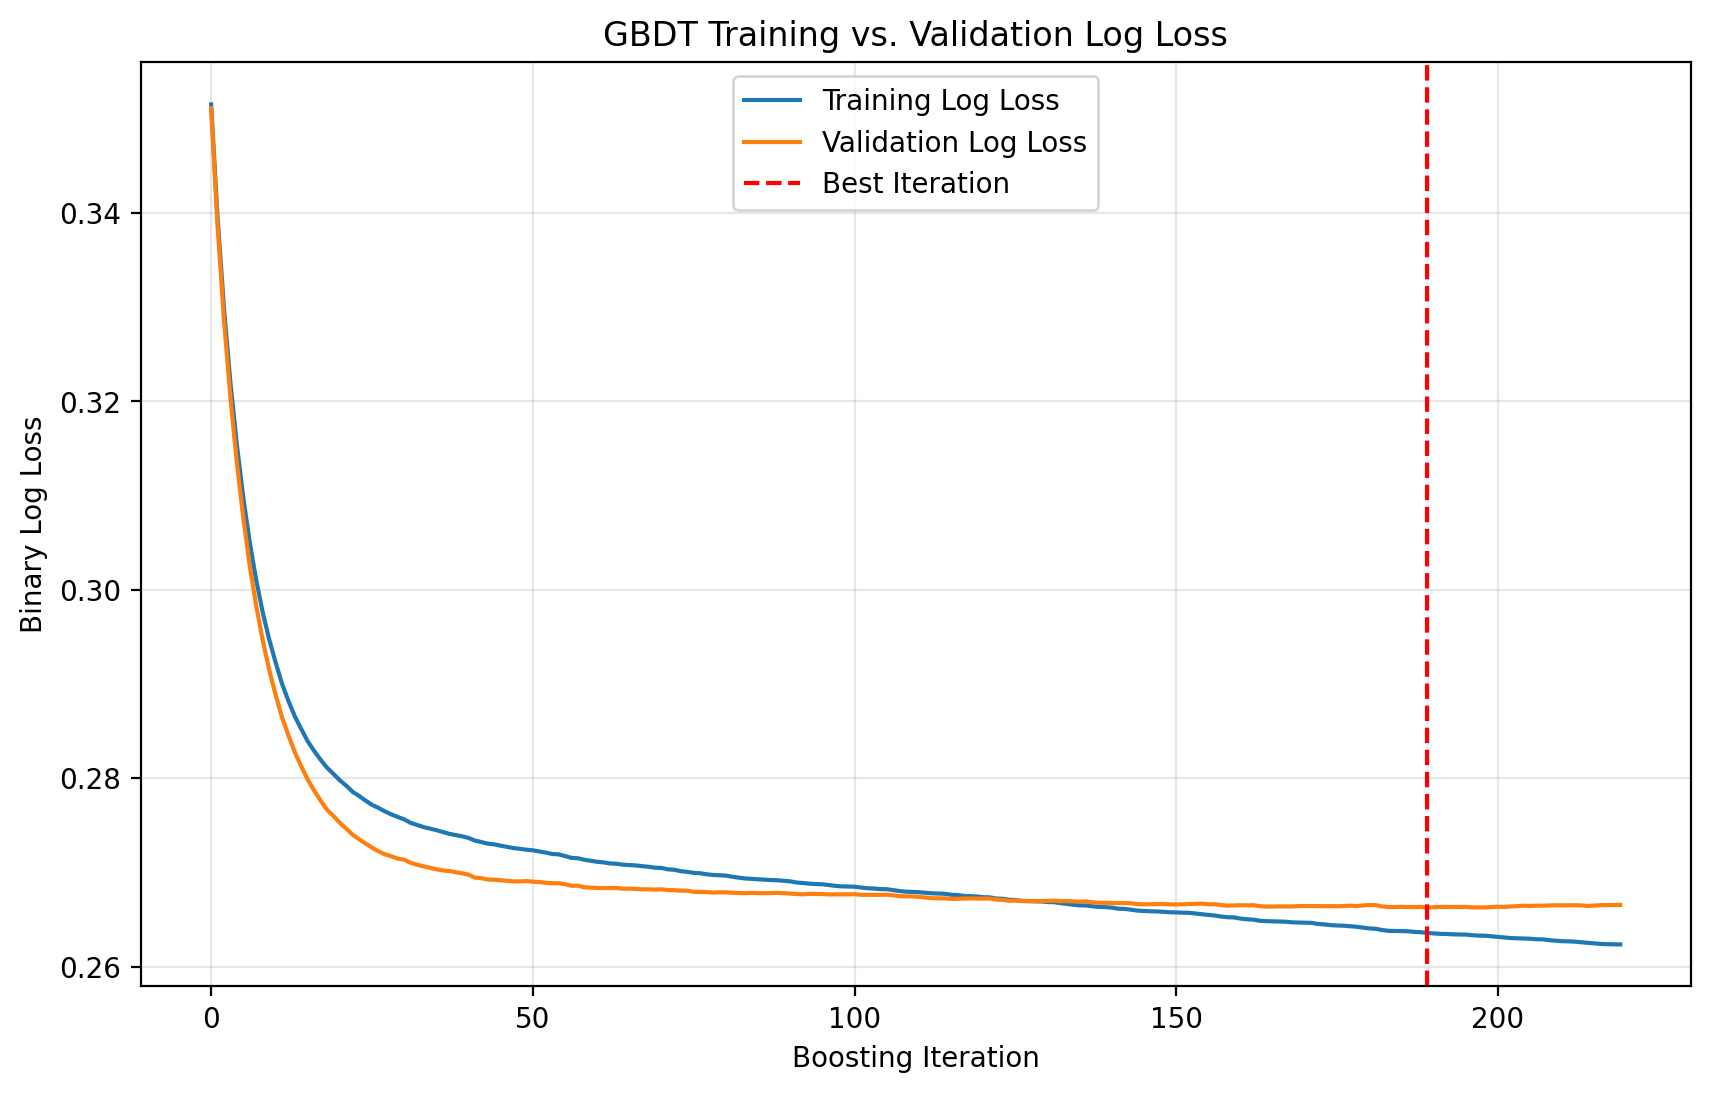

In [19]:
evals_result = best_gbdt_model.evals_result()

train_loss = evals_result["validation_0"]["logloss"]
val_loss = evals_result["validation_1"]["logloss"]

plt.figure(figsize=(10, 6))

plt.plot(train_loss, label="Training Log Loss")
plt.plot(val_loss, label="Validation Log Loss")

plt.axvline(
    best_gbdt_model.best_iteration,
    color="red",
    linestyle="--",
    label="Best Iteration"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Binary Log Loss")
plt.title("GBDT Training vs. Validation Log Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Plot Feature Importance

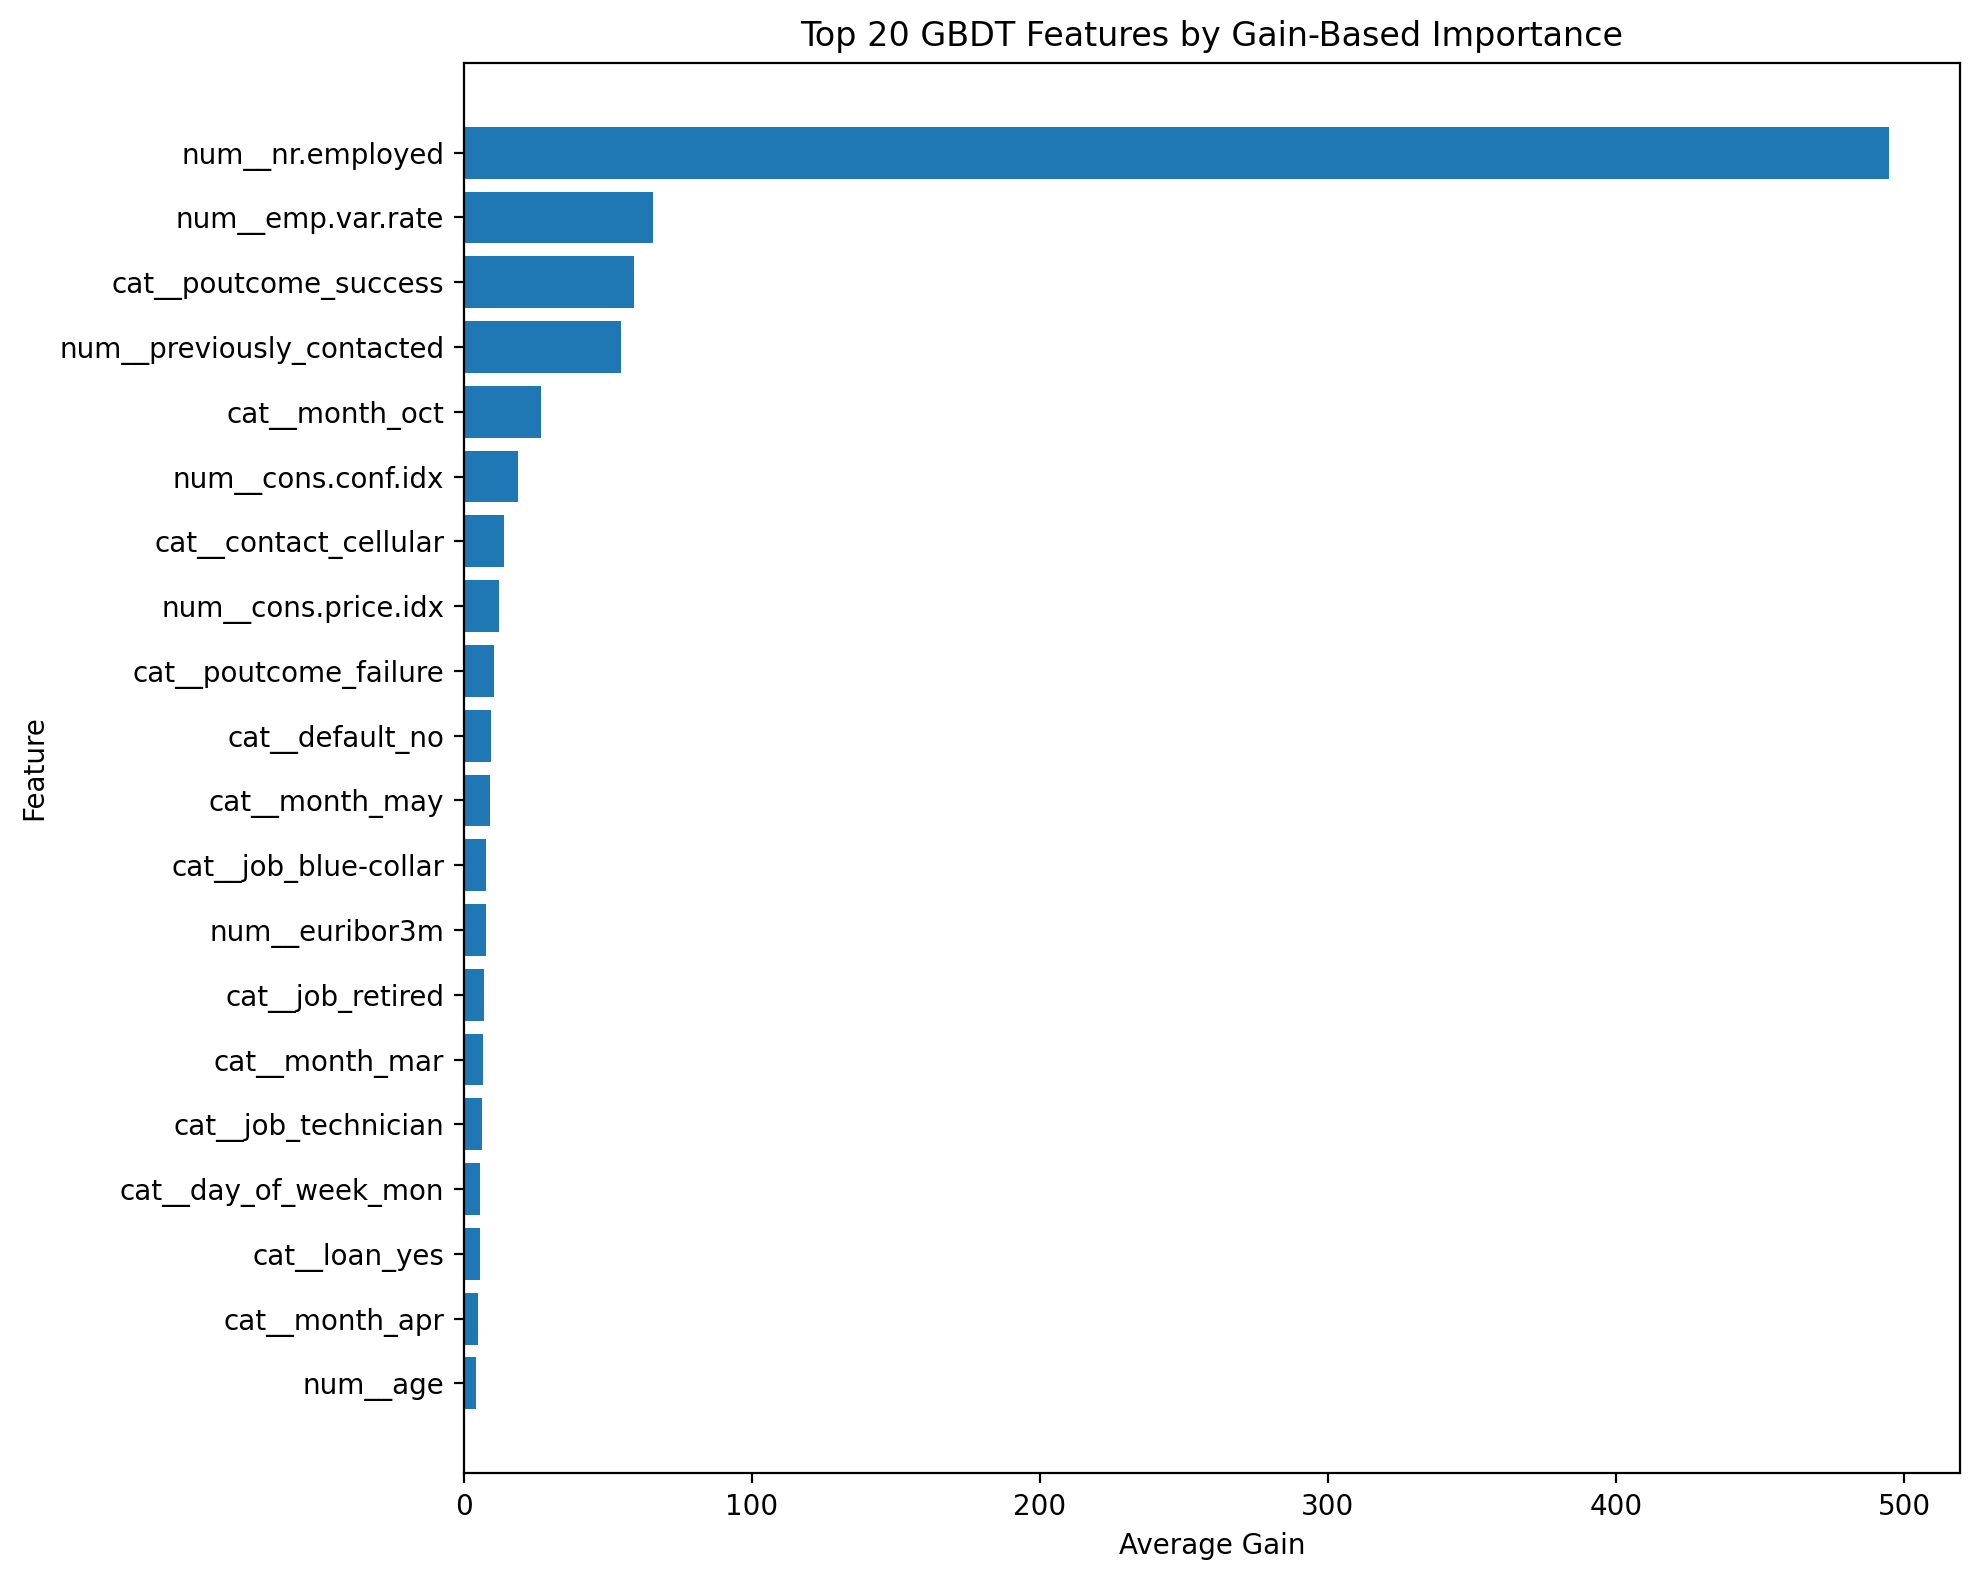

In [20]:
# Get transformed feature names
feature_names = preprocessor_gbdt.get_feature_names_out()

# Retrieve gain-based importance
importance_dict = best_gbdt_model.get_booster().get_score(
    importance_type="gain"
)

# Include features with zero importance
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": [
        importance_dict.get(f"f{i}", 0)
        for i in range(len(feature_names))
    ]
})

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

# Plot top 20 features
top_features = importance_df.head(20).sort_values(
    by="importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Average Gain")
plt.ylabel("Feature")
plt.title("Top 20 GBDT Features by Gain-Based Importance")
plt.tight_layout()
plt.show()

## Document the experimental environment

In [21]:
import platform
import sklearn

print("Python version:", platform.python_version())
print("Operating system:", platform.platform())
print("Processor:", platform.processor())
print("CPU cores:", __import__("os").cpu_count())

print("XGBoost version:", xgb.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("Random seed:", RANDOM_STATE)
print("Tree method: hist")
print("Device: CPU")

Python version: 3.10.7
Operating system: macOS-26.5.2-arm64-arm-64bit
Processor: arm
CPU cores: 8
XGBoost version: 2.1.4
Scikit-learn version: 1.5.2
Pandas version: 2.2.3
NumPy version: 1.26.4
Random seed: 42
Tree method: hist
Device: CPU
